In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
import pandas as pd
#Завантаження датасету
df = pd.read_csv("/content/cybersecurity_network_logs.csv")

print("--- Перші 5 рядків датасету ---")
print(df.head())


--- Перші 5 рядків датасету ---
  Protocol  Packet_Size_Bytes  Connection_Duration_ms  Failed_Logins  \
0      TCP                805                      59              0   
1      TCP                926                      58              0   
2      TCP                974                       3              0   
3     ICMP               6121                      16              0   
4      TCP                119                      64              1   

   Geo_Distance_km  Is_Malicious  
0             1169             0  
1              379             0  
2               79             0  
3             1044             1  
4              788             0  


# **ЗАВДАННЯ 1**

**Крок 1. Завантаження та первинний аналіз**

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import set_config

set_config(display="text")

# 1. Завантаження
df = pd.read_csv("/content/cybersecurity_network_logs.csv")
df.columns = df.columns.str.strip()

# Виводимо розмір та перші рядки
print("Shape:", df.shape)
print("Columns:", df.columns)
print("\nTarget distribution:")
print(df["Is_Malicious"].value_counts()) #цільова змінна
print("\nInfo:")
df.info()

Shape: (25000, 6)
Columns: Index(['Protocol', 'Packet_Size_Bytes', 'Connection_Duration_ms',
       'Failed_Logins', 'Geo_Distance_km', 'Is_Malicious'],
      dtype='object')

Target distribution:
Is_Malicious
0    23753
1     1247
Name: count, dtype: int64

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Protocol                25000 non-null  object
 1   Packet_Size_Bytes       25000 non-null  int64 
 2   Connection_Duration_ms  25000 non-null  int64 
 3   Failed_Logins           25000 non-null  int64 
 4   Geo_Distance_km         25000 non-null  int64 
 5   Is_Malicious            25000 non-null  int64 
dtypes: int64(5), object(1)
memory usage: 1.1+ MB


**Крок 2. Попередня обробка**

In [ ]:
from sklearn.preprocessing import OneHotEncoder

# Перевірка на пропуски
print("Missing values:")
print(df.isnull().sum())

# Кодування категоріальної колонки Protocol через OneHotEncoder
ohe = OneHotEncoder(sparse_output=False)
protocol_encoded = ohe.fit_transform(df[["Protocol"]])

protocol_df = pd.DataFrame(
    protocol_encoded,
    columns=ohe.get_feature_names_out(["Protocol"]),
    index=df.index,
)

# Формуємо підсумковий датасет без текстової колонки Protocol
df_processed = pd.concat([df.drop(columns=["Protocol"]), protocol_df], axis=1)
print("\nProcessed head:")
print(df_processed.head())

# Розділяємо на X та y
X = df_processed.drop("Is_Malicious", axis=1)
y = df_processed["Is_Malicious"]

Missing values:
Protocol                  0
Packet_Size_Bytes         0
Connection_Duration_ms    0
Failed_Logins             0
Geo_Distance_km           0
Is_Malicious              0
dtype: int64

Processed head:
   Packet_Size_Bytes  Connection_Duration_ms  Failed_Logins  Geo_Distance_km  \
0                805                      59              0             1169   
1                926                      58              0              379   
2                974                       3              0               79   
3               6121                      16              0             1044   
4                119                      64              1              788   

   Is_Malicious  Protocol_ICMP  Protocol_TCP  Protocol_UDP  
0             0            0.0           1.0           0.0  
1             0            0.0           1.0           0.0  
2             0            0.0           1.0           0.0  
3             1            1.0           0.0           0.0  


Кодування категоріальної ознаки (Protocol).
Текстовий стовпчик Protocol (зі значеннями TCP, UDP, ICMP) перетворено на 3 окремі числові колонки:
Protocol_ICMP
Protocol_TCP
Protocol_UDP
Значення в них - це двійковий код: 1.0 (якщо протокол використовувався) або 0.0 (якщо ні).
Текстову колонку Protocol видалено через .drop(), а нові стовпці приєднано через pd.concat().

Мережеві протоколи (TCP, UDP, ICMP) - це номінальні категорії, між якими немає природного порядку («кращий/гірший» або «більший/менший»).
Якби ми закодували їх числами 0, 1, 2, моделі, що розраховують математичні відстані (kNN та SVM), порахували б, що UDP (2) математично вдвічі більший за TCP (1), що спотворило б результати.
OneHotEncoder позбавляє моделі цього штучного впорядкування.

**Крок 3. Візуалізація даних**

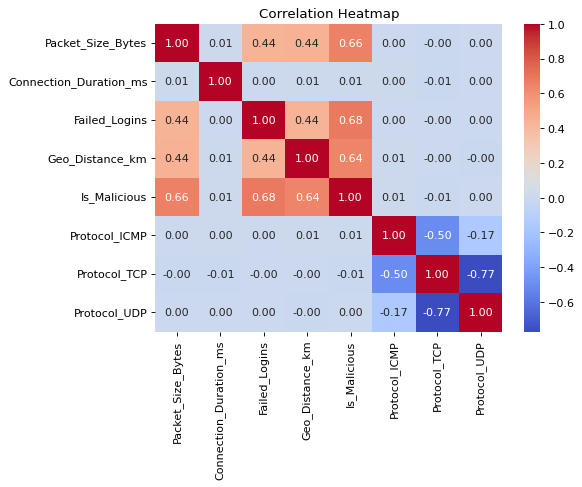

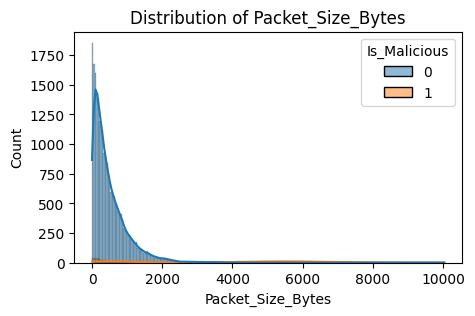

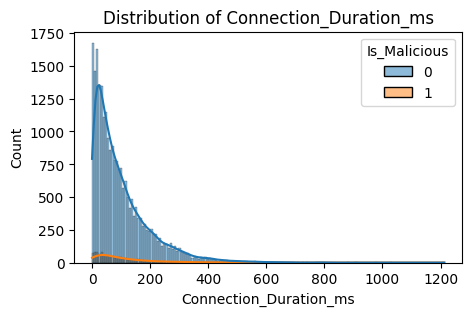

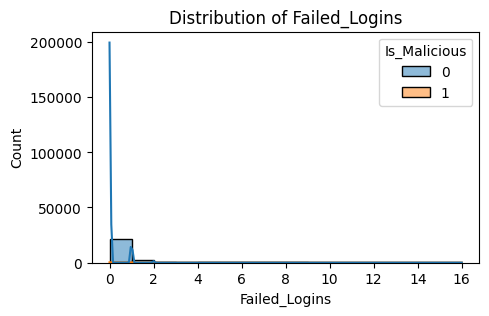

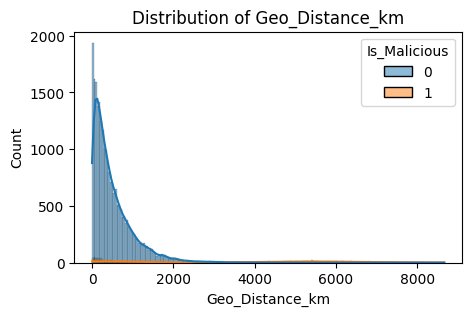

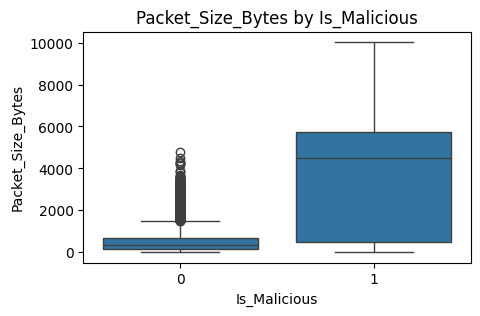

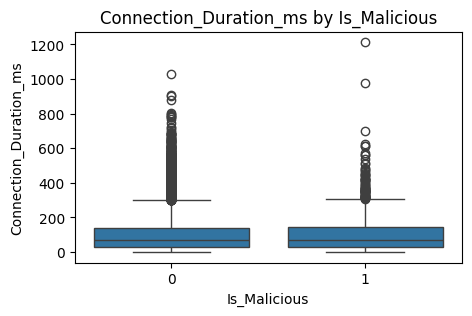

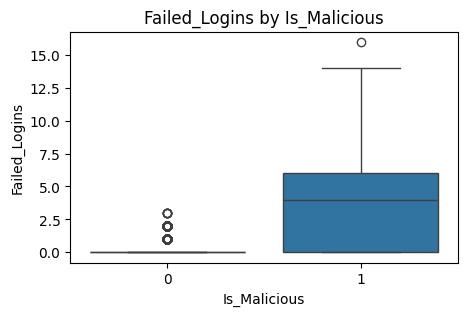

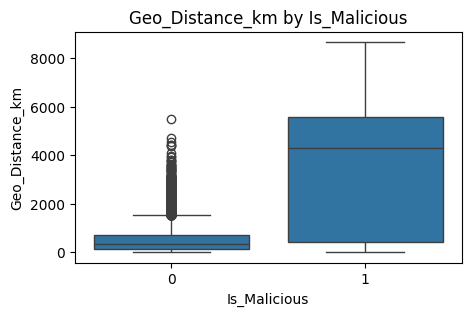

In [ ]:
# 1. Heatmap кореляцій
corr = df_processed.corr()
plt.figure(figsize=(7, 5), dpi=80)
sns.heatmap(corr, cmap="coolwarm", annot=True, fmt=".2f")
plt.title("Correlation Heatmap")
plt.show()

# 2. Гістограми розподілу
features_to_plot = [
    "Packet_Size_Bytes",
    "Connection_Duration_ms",
    "Failed_Logins",
    "Geo_Distance_km",
]
for col in features_to_plot:
    plt.figure(figsize=(5, 3))
    sns.histplot(data=df_processed, x=col, hue="Is_Malicious", kde=True)
    plt.title(f"Distribution of {col}")
    plt.show()

# 3. Boxplots ознак відносно цільової змінної
for col in features_to_plot:
    plt.figure(figsize=(5, 3))
    sns.boxplot(x="Is_Malicious", y=col, data=df_processed)
    plt.title(f"{col} by Is_Malicious")
    plt.show()

**Теплокарта кореляцій (Heatmap):**
Виявлено сильний додатний лінійний зв'язок між загрозами (Is_Malicious) та трьома ознаками: Failed_Logins (
r=0.68), Packet_Size_Bytes (r=0.66) і Geo_Distance_km (r=0.64).
Ознака Connection_Duration_ms (r=0.01) та закодовані протоколи (r≈0.00
) майже не мають лінійного зв'язку з фактом атаки.


**Гістограми розподілу (Distribution Plots):**
Усі числові ознаки мають правосторонню асиметрію - більшість сесій мають невеликі значення.
Наочно підтверджено сильний дисбаланс класів: помаранчеві графіки атак ледь помітні на фоні переважаючої більшості звичайного трафіку (блакитний колір).


**Діаграми розмаху (Boxplots):**

*Розмір пакета (Packet_Size_Bytes):*
для атак медіана становить близько 4500 байт (проти ~300 байт для норми).

*Невдалі входи (Failed_Logins):* для норми значення стабільно дорівнює 0, тоді як для атак ящик піднятий до 4–6 спроб (ознака брутфорс-атак).

*Відстань (Geo_Distance_km):* атаки надходять зі значно більшої відстані (медіана > 4000 км).

*Тривалість (Connection_Duration_ms):* ящики для норми та атак знаходяться на однаковому рівні (медіана ~70 мс), що підтверджує неінформативність цієї ознаки для класифікації.

**Крок 4. Train Test Split та масштабування**

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Розбиття зі збереженням пропорцій (stratify)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Стандартизація
scaler = StandardScaler()
scaler.fit(X_train)
scaled_X_train = scaler.transform(X_train)
scaled_X_test = scaler.transform(X_test)

# 1. Перевіряємо розмірності вибірок (скільки рядків пішло на навчання, скільки на тест)
print("Розмір X_train:", X_train.shape)
print("Розмір X_test: ", X_test.shape)

# 2. Дивимося на перші 2 рядки вже стандартизованих даних
print("\nПерші 2 рядки scaled_X_train (числа приведені до одного масштабу):")
print(scaled_X_train[:2])

# 3. Перевірка властивості StandardScaler: середнє ≈ 0, стандартне відхилення = 1
print("\nСереднє колонок (має бути ~ 0):", scaled_X_train.mean(axis=0).round(2))
print("Стандартне відхилення (має бути 1):", scaled_X_train.std(axis=0).round(2))

Розмір X_train: (20000, 7)
Розмір X_test:  (5000, 7)

Перші 2 рядки scaled_X_train (числа приведені до одного масштабу):
[[-0.17506636 -0.23140882  0.65299292  0.0126751  -0.32896418  0.6537965
  -0.50281094]
 [-0.51298656  0.39625857  0.65299292 -0.31299135 -0.32896418  0.6537965
  -0.50281094]]

Середнє колонок (має бути ~ 0): [ 0.  0.  0.  0.  0.  0. -0.]
Стандартне відхилення (має бути 1): [1. 1. 1. 1. 1. 1. 1.]


**Крок 5 та 6. Навчання та підбір гіперпараметрів**

**А. k-Nearest Neighbors (kNN) + Графік вибору K**

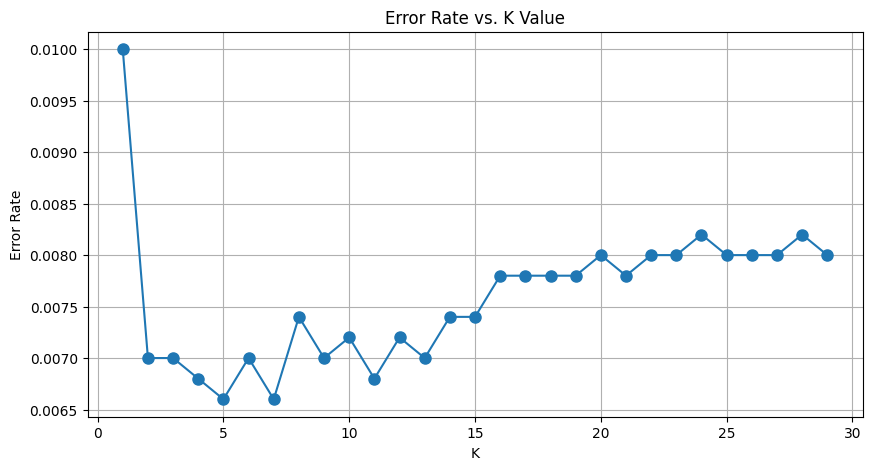

Optimal K: 5


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)
from sklearn.neighbors import KNeighborsClassifier

# Підбір K через графік Error Rate
error_rate = []
for i in range(1, 30):
    knn = KNeighborsClassifier(n_neighbors=i)
    knn.fit(scaled_X_train, y_train)
    pred_i = knn.predict(scaled_X_test)
    error_rate.append(np.mean(pred_i != y_test))

plt.figure(figsize=(10, 5))
plt.plot(range(1, 30), error_rate, marker="o", markersize=8)
plt.title("Error Rate vs. K Value")
plt.xlabel("K")
plt.ylabel("Error Rate")
plt.grid()
plt.show()

# Обираємо найкраще K з мінімальною помилкою
best_k = np.argmin(error_rate) + 1
print(f"Optimal K: {best_k}")

knn_final = KNeighborsClassifier(n_neighbors=best_k)
knn_final.fit(scaled_X_train, y_train)
knn_pred = knn_final.predict(scaled_X_test)

**Б. Decision Tree**

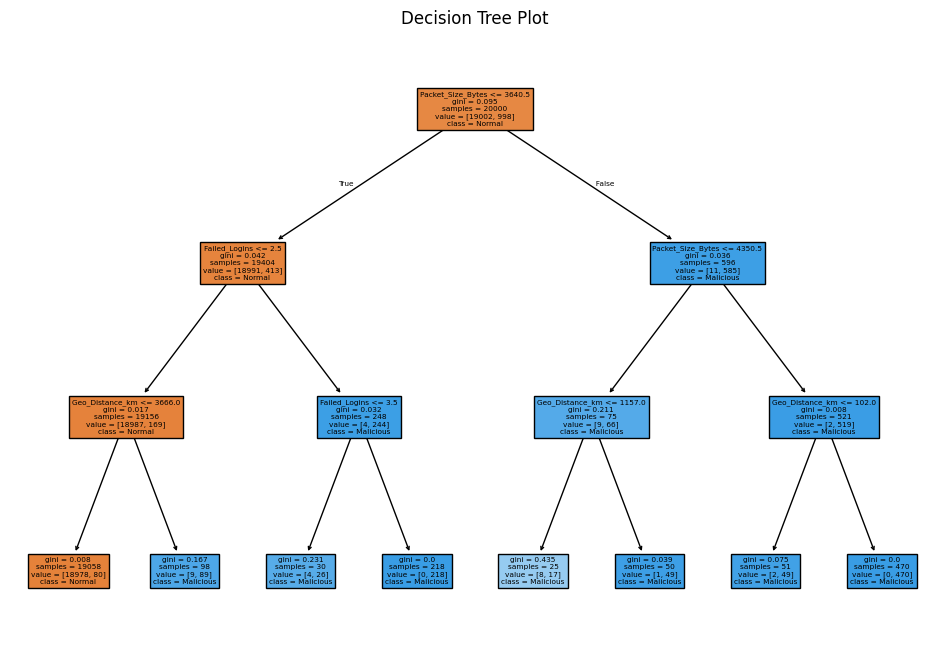

In [ ]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

dt_model = DecisionTreeClassifier(
    criterion="gini", max_depth=3, min_samples_leaf=2, random_state=42
)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

# Візуалізація дерева
plt.figure(figsize=(12, 8))
plot_tree(
    dt_model,
    feature_names=X.columns.tolist(),
    class_names=["Normal", "Malicious"],
    filled=True,
)
plt.title("Decision Tree Plot")
plt.show()

**В. Support Vector Machine (SVM) + GridSearchCV**

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

# Точна сітка параметрів
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [1, 0.1, 0.01, 0.001],
    "kernel": ["rbf"],
}

grid_svm = GridSearchCV(SVC(), param_grid, cv=5, refit=True)
grid_svm.fit(scaled_X_train, y_train)

print("Best SVM Params:", grid_svm.best_params_)
svm_pred = grid_svm.predict(scaled_X_test)

Best SVM Params: {'C': 1, 'gamma': 0.1, 'kernel': 'rbf'}


**Г. Random Forest та AdaBoost**

In [ ]:
from sklearn.ensemble import AdaBoostClassifier, RandomForestClassifier

# Random Forest
rf = RandomForestClassifier(n_estimators=50, random_state=42)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

# AdaBoost
ada = AdaBoostClassifier(n_estimators=50, random_state=42)
ada.fit(X_train, y_train)
ada_pred = ada.predict(X_test)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
)

# ==========================================
# 1. Результати для RANDOM FOREST
# ==========================================
print("=" * 25, "RANDOM FOREST", "=" * 25)
print(f"Accuracy: {accuracy_score(y_test, rf_pred):.4f}")

print("\nConfusion Matrix (Матриця помилок):")
print(confusion_matrix(y_test, rf_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test, rf_pred, target_names=["Норма (0)", "Загроза (1)"]
    )
)

# ==========================================
# 2. Результати для ADABOOST
# ==========================================
print("\n" + "=" * 25, "ADABOOST", "=" * 25)
print(f"Accuracy: {accuracy_score(y_test, ada_pred):.4f}")

print("\nConfusion Matrix (Матриця помилок):")
print(confusion_matrix(y_test, ada_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test, ada_pred, target_names=["Норма (0)", "Загроза (1)"]
    )
)

========================= RANDOM FOREST =========================
Accuracy: 0.9946

Confusion Matrix (Матриця помилок):
[[4747    4]
 [  23  226]]

Classification Report:
              precision    recall  f1-score   support

   Норма (0)       1.00      1.00      1.00      4751
 Загроза (1)       0.98      0.91      0.94       249

    accuracy                           0.99      5000
   macro avg       0.99      0.95      0.97      5000
weighted avg       0.99      0.99      0.99      5000


========================= ADABOOST =========================
Accuracy: 0.9946

Confusion Matrix (Матриця помилок):
[[4747    4]
 [  23  226]]

Classification Report:
              precision    recall  f1-score   support

   Норма (0)       1.00      1.00      1.00      4751
 Загроза (1)       0.98      0.91      0.94       249

    accuracy                           0.99      5000
   macro avg       0.99      0.95      0.97      5000
weighted avg       0.99      0.99      0.99      5000



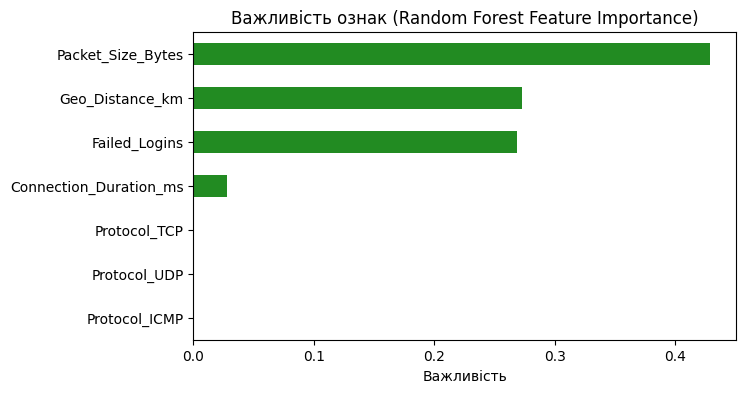

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# Важливість ознак для Random Forest
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(
    ascending=True
)

plt.figure(figsize=(7, 4))
importances.plot(kind="barh", color="forestgreen")
plt.title("Важливість ознак (Random Forest Feature Importance)")
plt.xlabel("Важливість")
plt.show()

**Крок 7. Оцінювання та порівняння (Classification Report + Confusion Matrix)**

In [ ]:
all_predictions = {
    "kNN": knn_pred,
    "Decision Tree": dt_pred,
    "SVM (GridSearch)": svm_pred,
    "Random Forest": rf_pred,
    "AdaBoost": ada_pred,
}

# Вивід звіту та матриці помилок для кожної моделі
for name, preds in all_predictions.items():
    print(f"\n{'='*20} {name} {'='*20}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, preds))
    print("\nClassification Report:")
    print(classification_report(y_test, preds))
    print(f"Accuracy Score: {accuracy_score(y_test, preds):.4f}")


==================== kNN ====================
Confusion Matrix:
[[4748    3]
 [  30  219]]

Classification Report:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00      4751
           1       0.99      0.88      0.93       249

    accuracy                           0.99      5000
   macro avg       0.99      0.94      0.96      5000
weighted avg       0.99      0.99      0.99      5000

Accuracy Score: 0.9934

==================== Decision Tree ====================
Confusion Matrix:
[[4745    6]
 [  20  229]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00      4751
           1       0.97      0.92      0.95       249

    accuracy                           0.99      5000
   macro avg       0.99      0.96      0.97      5000
weighted avg       0.99      0.99      0.99      5000

Accuracy Score: 0.9948

==================== SVM (GridSearch) ===================


Хибна тривога (False Positive, FP): система помилково заблокувала звичайного користувача.
Пропущена атака (False Negative, FN): хакер проник у систему непоміченим — це найнебезпечніша помилка.
Що показали моделі:
Decision Tree показало найкращу повноту виявлення (Recall = 0.92): воно пропустило найменше атак (усього 20 з 249).
SVM та kNN показали найвищу точність спрацювань (Precision = 0.99), давши мінімум хибних тривог (лише 2–3 випадки), але пропустили дещо більше атак (30–31 сесію).
Random Forest та AdaBoost продемонстрували збалансовану роботу між точністю та повнотою (F1-score = 0.94).

У ході виконання завдання було навчено та налаштовано 5 класифікаторів машинного навчання. Усі моделі показали високу загальну точність (Accuracy > 99.3%).
Найкращою моделлю для обраного датасету виявилося Дерево рішень (Decision Tree), яке досягло найвищого значення F1-score = 0.95, точності Accuracy = 0.9948 та найбільшого охоплення загроз Recall = 0.92 (пропущено лише 20 атак із 249).
Чому Decision Tree найкраще підходить для цих даних:
Структура мережевих аномалій у цьому датасеті базується на чітких порогових правилах: якщо розмір пакета >3640.5 байт або кількість невдалих спроб входу >2, це майже напевно атака.
Дерево рішень за своєю природою ідеально знаходить саме такі ортогональні пороги (If-Else), тоді як геометричні методи (SVM, kNN), що використовують плавні гіперплощини та радіуси відстаней, сильніше страждають від дисбалансу класів (95% норми проти 5% атак) і тому дещо частіше пропускають загрози.
Крім того, Decision Tree є інтерпретованою моделлю («білою скринькою»), правила якої системний адміністратор може безпосередньо інтегрувати в правила фаєрволу.

# **ЗАВДАННЯ 2**

**Частина 1. Зниження розмірності (PCA, порівняння часу, t-SNE)**

=== Порівняння до/після PCA ===
Початкова к-ть ознак: 7 -> Залишено компонент: 6
kNN без PCA  -> Accuracy: 0.9934 | Час навчання: 0.029640s
kNN з PCA    -> Accuracy: 0.9934 | Час навчання: 0.044972s

Обчислення t-SNE (може зайняти кілька секунд)...


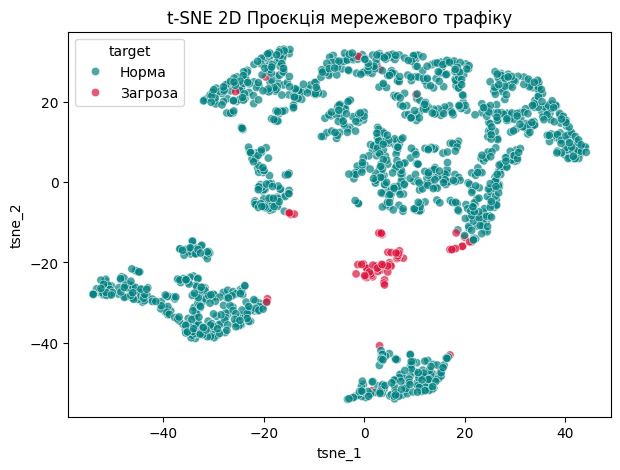

In [ ]:
import time
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import accuracy_score, classification_report
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 1. Порівняння класифікації: kNN без PCA проти kNN з PCA (з вимірюванням часу)
# Використовуємо X_train, X_test, y_train, y_test із Завдання 1

# Модель 1: Без PCA (лише масштабування + kNN)
pipe_knn = Pipeline(
    [("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=5))]
)

t0 = time.perf_counter()
pipe_knn.fit(X_train, y_train)
t1 = time.perf_counter()
knn_preds = pipe_knn.predict(X_test)
t_pred = time.perf_counter() - t1
knn_fit_time = t1 - t0

# Модель 2: З PCA (зберігаємо 95% дисперсії)
pipe_pca_knn = Pipeline(
    [
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.95, random_state=42)),
        ("knn", KNeighborsClassifier(n_neighbors=5)),
    ]
)

t0 = time.perf_counter()
pipe_pca_knn.fit(X_train, y_train)
t1 = time.perf_counter()
pca_preds = pipe_pca_knn.predict(X_test)
pca_pred_time = time.perf_counter() - t1
pca_fit_time = t1 - t0

pca_step = pipe_pca_knn.named_steps["pca"]
print("=== Порівняння до/після PCA ===")
print(
    f"Початкова к-ть ознак: {X_train.shape[1]} -> Залишено компонент: {pca_step.n_components_}"
)
print(f"kNN без PCA  -> Accuracy: {accuracy_score(y_test, knn_preds):.4f} | Час навчання: {knn_fit_time:.6f}s")
print(f"kNN з PCA    -> Accuracy: {accuracy_score(y_test, pca_preds):.4f} | Час навчання: {pca_fit_time:.6f}s")

# 2. Зниження розмірності через t-SNE до 2D та візуалізація
print("\nОбчислення t-SNE (може зайняти кілька секунд)...")
tsne = TSNE(n_components=2, perplexity=30.0, random_state=42)
tsne_result = tsne.fit_transform(scaled_X_train[:1500])  # беремо зріз для швидкої візуалізації

tsne_df = pd.DataFrame(
    {
        "tsne_1": tsne_result[:, 0],
        "tsne_2": tsne_result[:, 1],
        "target": y_train.iloc[:1500].map({0: "Норма", 1: "Загроза"}),
    }
)

plt.figure(figsize=(7, 5))
sns.scatterplot(
    x="tsne_1",
    y="tsne_2",
    hue="target",
    data=tsne_df,
    palette=["teal", "crimson"],
    alpha=0.7,
)
plt.title("t-SNE 2D Проєкція мережевого трафіку")
plt.show()

Для датасету мережевих логів було застосовано алгоритм PCA з порогом збереження 95% дисперсії, що дозволило скоротити простір ознак із 7 до 6 головних компонентів, відкинувши 1 малоінформативну компоненту шуму.

Порівняння базового класифікатора kNN (K=5) показало, що якість розпізнавання до та після стиснення даних залишилася незмінною - точність (Accuracy) в обох випадках становить 0.9934 (99.34%), що підтверджує збереження всієї значущої структури вибірки.

Час навчання моделі дещо зріс (з 0.029640 с до 0.044972 с), оскільки за відносно малої початкової кількості ознак (7 колонок) математичні витрати на проєкцію PCA перевищили виграш від зменшення розмірності на один стовпчик.

Для дослідження просторової структури даних було виконано нелінійне проєктування у 2D за допомогою t-SNE: на графіку спостереження класу «Загроза» (малинові точки) згрупувалися у компактний відокремлений кластер у нижній правій частині площини (tsne_1≈5, tsne_2≈−20), практично не змішуючись із масивом нормального трафіку.

Це наочно доводить відмінну геометричну подільність класів та пояснює успішність навчених моделей машинного навчання.

**Частина 2. Кластерний аналіз (K-Means, Elbow plot, Silhouette score)**

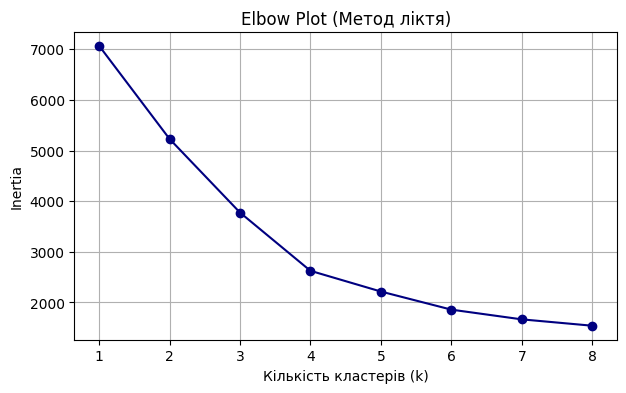

--- Silhouette Score для різної к-ті кластерів ---
Для k = 2 | Silhouette Score = 0.4670
Для k = 3 | Silhouette Score = 0.5046
Для k = 4 | Silhouette Score = 0.5854
Для k = 5 | Silhouette Score = 0.4859


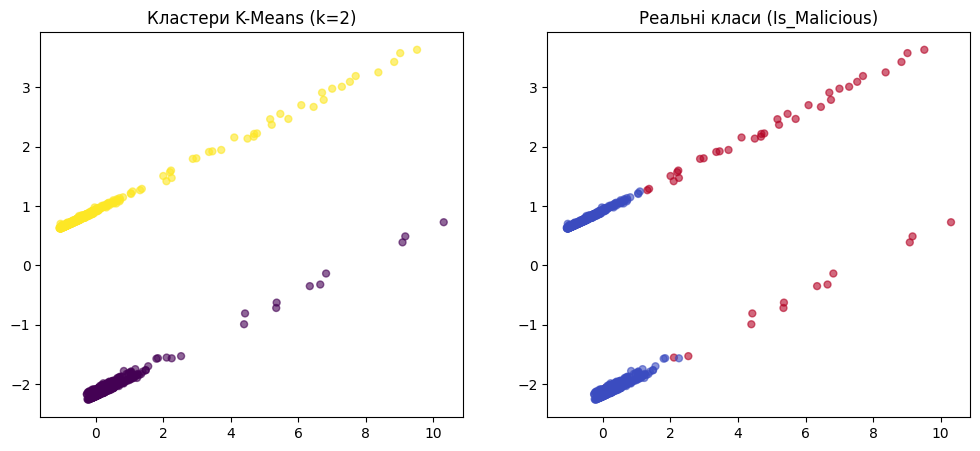

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Для кластеризації використовуємо лише ознаки (без міток target!)
X_cluster = scaled_X_train[:1000]  # беремо 1000 точок для наочності
y_cluster = y_train.iloc[:1000]

# 1. Elbow Method (Метод ліктя)
errors = []
K_range = range(1, 9)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_cluster)
    errors.append(km.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(K_range, errors, marker="o", color="navy")
plt.title("Elbow Plot (Метод ліктя)")
plt.xlabel("Кількість кластерів (k)")
plt.ylabel("Inertia")
plt.grid(True)
plt.show()

# 2. Silhouette Score
print("--- Silhouette Score для різної к-ті кластерів ---")
for k in range(2, 6):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_cluster)
    score = silhouette_score(X_cluster, labels)
    print(f"Для k = {k} | Silhouette Score = {score:.4f}")

# 3. Навчання фінального K-Means (k=2, оскільки маємо 2 класи)
kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(X_cluster)

# 4. Візуалізація через PCA: Знайдені кластери VS Реальні класи
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_cluster)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Графік 1: Що знайшов K-Means
ax1.scatter(
    X_pca_2d[:, 0],
    X_pca_2d[:, 1],
    c=cluster_labels,
    cmap="viridis",
    alpha=0.6,
    s=25,
)
ax1.set_title("Кластери K-Means (k=2)")

# Графік 2: Справжні класи датасету
ax2.scatter(
    X_pca_2d[:, 0],
    X_pca_2d[:, 1],
    c=y_cluster,
    cmap="coolwarm",
    alpha=0.6,
    s=25,
)
ax2.set_title("Реальні класи (Is_Malicious)")

plt.show()

На основі масштабованих ознак мережевого трафіку без використання цільової мітки було проведено кластеризацію алгоритмом K-Means. Оцінка доцільної кількості кластерів за допомогою методів Elbow Method та Silhouette Score показала математичний оптимум при k=4 (коефіцієнт силуету сягнув пікового значення 0.5854). Для перевірки відповідності кластерної структури реальним класам датасету модель було також навчено для випадку k=2.

Порівняння засвідчило, що знайдена структура не відповідає реальним міткам класів: через різницю у типах мережевих протоколів алгоритм без учителя згрупував сесії у дві паралельні просторові смуги (розбиття за домінуючою геометричною відстанню), тоді як реальні загрози (Is_Malicious = 1) локалізовані у правій витягнутій частині обох смуг завдяки аномальним значенням розміру пакетів і невдалих спроб входу. Це практично підтверджує, що кластер і клас є різними сутностями, а алгоритми навчання без учителя шукають внутрішню подібність у просторі ознак, яка не зобов'язана збігатися з цільовою функцією класифікації.

**Частина 3. Обробка та класифікація текстів (NLP)**

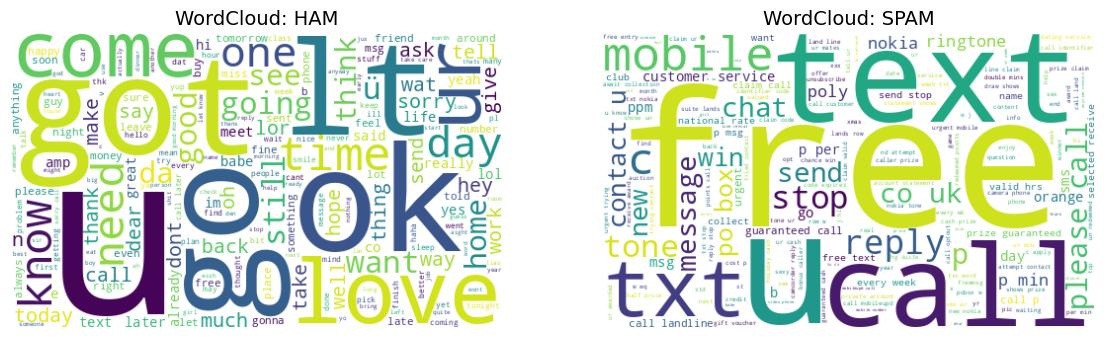


--- Звіт класифікації текстів (MultinomialNB + TF-IDF) ---
              precision    recall  f1-score   support

         ham       0.99      0.99      0.99       966
        spam       0.95      0.91      0.93       149

    accuracy                           0.98      1115
   macro avg       0.97      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



In [ ]:
import re
import string
import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from wordcloud import WordCloud

# Завантажуємо стоп-слова
nltk.download("stopwords", quiet=True)
stop_words = set(stopwords.words("english"))


# 1. Функція очищення тексту за скріншотом
def clean_text(text):
    text = text.lower()
    text = re.sub(r"@\S+", " ", text)
    text = re.sub(r"https*\S+", " ", text)
    text = re.sub(r"#\S+", " ", text)
    text = re.sub(r"\d", " ", text)
    text = re.sub(r"[%s]" % re.escape(string.punctuation), " ", text)
    text = re.sub(r"\s{2,}", " ", text)
    text = " ".join([word for word in text.split() if word not in stop_words])
    return text


# 2. Завантажуємо датасет SMS Spam
url = "https://raw.githubusercontent.com/justmarkham/pycon-2016-tutorial/master/data/sms.tsv"
df_text = pd.read_csv(url, sep="\t", header=None, names=["target", "text"])
df_text["clean_text"] = df_text["text"].apply(clean_text)

# 3. Візуалізація WordCloud для spam та ham
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for idx, label in enumerate(["ham", "spam"]):
    text_data = " ".join(df_text[df_text["target"] == label]["clean_text"])
    wc = WordCloud(
        width=500, height=300, background_color="white"
    ).generate(text_data)
    axes[idx].imshow(wc, interpolation="bilinear")
    axes[idx].axis("off")
    axes[idx].set_title(f"WordCloud: {label.upper()}", fontsize=14)
plt.show()

# 4. Train/Test split та векторизація через TfidfVectorizer
X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(
    df_text["clean_text"], df_text["target"], test_size=0.2, random_state=42
)

tfidf = TfidfVectorizer(max_features=2000)
X_train_tfidf = tfidf.fit_transform(X_train_t)
X_test_tfidf = tfidf.transform(X_test_t)

# 5. Класифікація через MultinomialNB
nb = MultinomialNB(alpha=0.1)
nb.fit(X_train_tfidf, y_train_t)
text_preds = nb.predict(X_test_tfidf)

print("\n--- Звіт класифікації текстів (MultinomialNB + TF-IDF) ---")
print(classification_report(y_test_t, text_preds))

Для виконання аналізу було завантажено корпус повідомлень SMS Spam Collection та проведено комплексну передобробку текстів: нормалізацію регістру, фільтрацію регулярними виразами веб-посилань, цифр і пунктуації, а також видалення стоп-слів бібліотеки NLTK. Візуалізація WordCloud продемонструвала виразну семантичну різницю між класами: лексика звичайних повідомлень (ham) зосереджена на персональному спілкуванні (u, ok, come, love, got), тоді як спам (spam) містить виключно рекламні та маніпулятивні маркери терміновості й вигоди (free, txt, call, claim, prize, mobile). Після розбиття вибірки на тренувальну й тестову (80/20) тексти було векторизовано за допомогою TfidfVectorizer (2000 ознак) та класифіковано моделлю наївного Байєса MultinomialNB (α=0.1).

Отримана модель продемонструвала відмінну якість: загальну точність Accuracy = 0.98, точність виявлення спаму Precision = 0.95, охоплення Recall = 0.91 та зведений показник F1-Score = 0.93, що підтверджує високу ефективність комбінації TF-IDF та байєсівської класифікації для задач фільтрації текстового спаму.